# primus-paleo — 03: the externals

Notebooks 01 and 02 used what ships in `Data/`. This one makes new inputs from scratch:

1. **a new flux scenario**: build a template with MCEq, or hand-make one from arrays, and use it in a `FluxHistory`;
2. **a new material**: write it in the mineral library, run Geant4 for every particle, export the range tables,
   and create a `Paleodetector` that reads the runs just made.

**Requirements** (on top of `pip install -e ".[plot]"`):
* Geant4 ≥ 11.2 (e.g. `conda install -c conda-forge geant4`) and the application in `geant4/` built once
  (README: `cmake ... && make`);
* MCEq, only to *build* flux templates. The package needs a recent MCEq: the observation-height handling
  (`EarthGeometry.set_h_obs`) is in MCEq's GitHub master, not in the 1.4.x releases on PyPI
  (`pip install git+https://github.com/mceq-project/MCEq`).

The Geant4 runs here are **deliberately tiny** (1000 events, a handful of low energies per particle), so that the
whole notebook runs in ~40 min on a laptop — most of it the range tables. The Geant4 runs are always executed
(they are the point of the notebook); the final integration (⏱) saves its result in `demo_cache/` and loads it on
later runs, unless `RERUN = True` in the first cell. The numbers they give are not physics;
the point is the plumbing, and how the detector reacts to different run grids.

In [ ]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import primus_paleo as pp

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False, "font.size": 11})
Path("figures").mkdir(exist_ok=True)          # slide-ready PNGs are saved here

RERUN = True                               # True: recompute every slow cell and overwrite its file
CACHE = Path("demo_cache"); CACHE.mkdir(exist_ok=True)

print("primus_paleo", pp.__version__)
pp.describe()

primus_paleo 0.1.0
data root           /home/claudio/primus-paleo/Data  (ok)
mineral library     /home/claudio/primus-paleo/Data/mineral_library.yaml  (ok)
flux templates      /home/claudio/primus-paleo/Data/flux_data  (ok)
Geant4 outputs      /home/claudio/primus-paleo/Data/Geant4_data  (ok)
Geant4 application  /home/claudio/primus-paleo/geant4/build/Run  (ok)


In [2]:
import json, os, shutil, time
print("geant4-config on PATH:", shutil.which("geant4-config"))
print("Geant4 application   :", pp.geant4_paths()["executable"], os.path.exists(pp.geant4_paths()["executable"]))

geant4-config on PATH: /home/claudio/miniforge3/envs/paleo/bin/geant4-config
Geant4 application   : /home/claudio/primus-paleo/geant4/build/Run True


# Part 1 — a new flux scenario

## 1.1 What a template is

A `FluxTemplate` is a grid of fluxes at ground level for every species (μ±, n, p, the four neutrinos, and the
primary): one spectrum for a **steady** template (a baseline), or a (time × energy) grid for a **transient** one,
which is the *excess* over the baseline after an event. `FluxHistory` adds them up.

Templates live in `Data/flux_data/` (or any `template_dir`), named after their parameters:
`{"kind": "SN", "distance_pc": 100.0}` → `SN_100.0_5.0GV.npz`, `h_obs_km` adds `_1.0km`.
`FluxTemplate.get_or_build(params)` loads the file if it is there, and otherwise builds it with MCEq and saves it.

In [3]:
for f in sorted(os.listdir(pp.flux_template_dir())):
    print(f)

Baseline_0.0GV_1.0km.npz
Baseline_5.0GV.npz
Baseline_5.0GV_1.0km.npz
Baseline_5.0GV_11.0km.npz
Resconi.txt
SN_100.0_5.0GV.npz
SN_20.0_5.0GV.npz
SN_250.0_0.0GV_1.0km.npz
SN_250.0_5.0GV_1.0km.npz


## 1.2 Building a template with MCEq

Two settings matter:
* the MCEq energy grid must start at ~0.1 GeV (`MCEq.config.e_min = 0.1`): below it the package splices measured
  low-energy shapes for nucleons and neutrinos, and it matches them at 0.2–7 GeV. The shipped templates were built
  this way; MCEq's current default (5 GeV) makes the build fail;
* the database `mceq_db_lext_dpm193_v142.h5` is downloaded on first use (~280 MB).

A steady template takes ~2–3 min. A **transient** one solves MCEq once per time step (default: 250 steps over
500 kyr), ~1–2 min each: hours, so build those once, on a big machine, and keep the file.

Here we build two baselines **with the same MCEq**, at 5 GV and 2 GV, into a demo folder (not into `Data/`).
`get_or_build` saves them in `demo_flux_templates/`: the first run builds them (⏱ ~5 min), later runs load the files.

In [4]:
try:
    import MCEq.config
    MCEq.config.e_min = 0.1            # GeV: needed by the low-energy splice (see above)
except ImportError:
    print("MCEq not installed: only templates already saved can be loaded")

DEMO_TEMPLATES = Path("demo_flux_templates").resolve()
t0 = time.time()
base5 = pp.FluxTemplate.get_or_build({"kind": "Baseline"}, template_dir=str(DEMO_TEMPLATES))
base2 = pp.FluxTemplate.get_or_build({"kind": "Baseline", "geomagnetic_cutoff": 2.0}, template_dir=str(DEMO_TEMPLATES))
print(f"{base5.name}, {base2.name} ready in {time.time() - t0:.0f} s; species: {base5.species}")

Baseline_5.0GV, Baseline_2.0GV ready in 0 s; species: ['primary', 'mu+', 'mu-', 'neutron', 'proton', 'nu_mu', 'anti_nu_mu', 'nu_e', 'anti_nu_e']


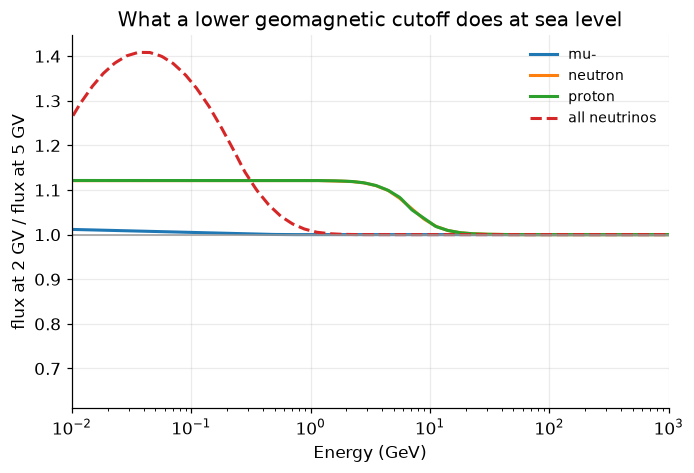

In [5]:
E = np.logspace(-3, 3, 400)
fig, ax = plt.subplots(figsize=(7, 4.4))
for s in ["mu-", "neutron", "proton"]:
    ax.semilogx(E, base2.flux(s, E) / base5.flux(s, E), lw=2, label=s)
nu2 = sum(base2.flux(s, E) for s in pp.NEUTRINO_SPECIES)
nu5 = sum(base5.flux(s, E) for s in pp.NEUTRINO_SPECIES)
ax.semilogx(E, nu2 / nu5, lw=2, ls="--", label="all neutrinos")
ax.axhline(1, color="0.6", lw=1)
ax.set(xlabel="Energy (GeV)", ylabel="flux at 2 GV / flux at 5 GV",
       title="What a lower geomagnetic cutoff does at sea level", xlim=(1e-2, 1e3))
ax.legend(fontsize=9)
fig.savefig("figures/15_cutoff_2GV_vs_5GV.png", dpi=200, bbox_inches="tight")
plt.show()

The cutoff removes low-rigidity primaries, which make few sea-level muons above ~1 GeV: the muons barely move.
The nucleons (n and p overlap) change by ~12% below a few GeV through the cutoff scaling of the low-energy splice
(Desilets et al. 2006, applied by the package). Below ~0.2 GeV the neutrinos are an indicative continuation of the
MCEq spectrum (`NEUTRINO_LOW_E`), re-fitted on each solution: the swing of their ratio there comes from that
extension, not from the physics of the cutoff.

**Reproducibility note:** a template depends on the MCEq version and database. These two (MCEq 2.0.0.dev) differ
from the shipped `Baseline_5.0GV.npz` by up to ~8% for nucleons and ~10% for sub-GeV muons, so compare templates
built with the same MCEq.

## 1.3 Building a transient template (not run here)

Same call, with a `kind` that has a time profile: `"SN"` (a supernova at `distance_pc`, Hillas–Gaisser-like
source spectrum diffusing to Earth) or `"Egal"`. The time grid is `np.linspace(1, tcut, min(250, tcut / 200))`
**in years** (`tcut` defaults to 500 000 yr), each step one MCEq solve.

In [6]:
BUILD_TRANSIENT = False      # hours: one MCEq solve per time step
if BUILD_TRANSIENT:
    sn50 = pp.FluxTemplate.get_or_build({"kind": "SN", "distance_pc": 50.0})          # -> Data/flux_data/SN_50.0_5.0GV.npz

## 1.4 A hand-made template (no MCEq)

Any flux model — another propagation code, a parametrisation from a paper — can enter as a `FluxTemplate` built
from arrays: a name, an energy grid (GeV), a dict of grids per species, and for a transient the time since the
event. **Units:** fluxes in cm⁻² s⁻¹ GeV⁻¹ (through a horizontal surface, as the MCEq templates);
the time axis `t_since_kyr` is, despite its name, in **years** (`FluxHistory` converts kyr to yr before reading it).

Example: a burst that adds 50% to every species and decays with τ = 20 kyr.

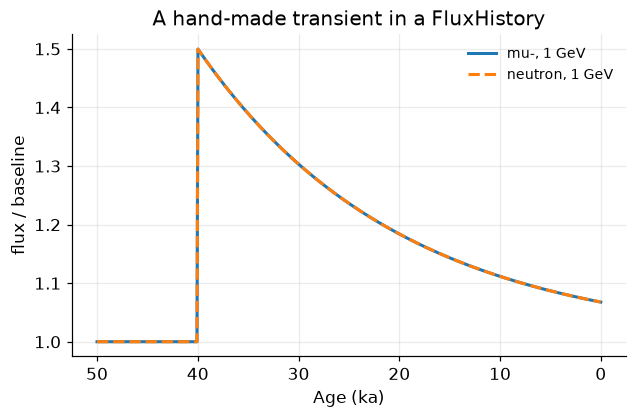

In [7]:
ref = base5                                         # the baseline the burst is added to, for the shape
t_years = np.linspace(0, 200e3, 201)
tau_years = 20e3
burst_grids = {s: 0.5 * np.exp(-t_years / tau_years)[:, None] * ref.flux(s, ref.energy_gev)[None, :]
               for s in ref.species if s != "primary"}
burst = pp.FluxTemplate("Burst50_tau20kyr", ref.energy_gev, burst_grids, t_since_kyr=t_years)
burst.save(str(DEMO_TEMPLATES / "Burst50_tau20kyr.npz"))           # reusable by name with template_dir=

AGE_KYR = 50.0
with_burst = pp.FluxHistory(events=[{"start_time_kyr": -40.0, "template": "Burst50_tau20kyr", "label": "burst"}],
                            template_dir=str(DEMO_TEMPLATES))
# the baseline of with_burst is loaded from demo_flux_templates too (Baseline_5.0GV built above)
plain = pp.FluxHistory(template_dir=str(DEMO_TEMPLATES))

t = np.linspace(-AGE_KYR, 0, 500)
fig, ax = plt.subplots(figsize=(6.5, 3.8))
for s in ["mu-", "neutron"]:
    ax.plot(-t, with_burst.flux(s, np.full_like(t, 1.0), t) / plain.flux(s, np.full_like(t, 1.0), t),
            lw=2, ls="-" if s == "mu-" else "--", label=f"{s}, 1 GeV")
ax.invert_xaxis()
ax.set(xlabel="Age (ka)", ylabel="flux / baseline", title="A hand-made transient in a FluxHistory")
ax.legend(fontsize=9)
fig.savefig("figures/16_handmade_burst.png", dpi=200, bbox_inches="tight")
plt.show()

# Part 2 — a new material

Gypsum (CaSO₄·2H₂O): one of the PRImuS targets, with no runs yet.

## 2.1 Write it in the mineral library

`pp.add_material` adds (or overwrites) an entry of `Data/mineral_library.yaml`. The (α,n) coefficient here is a
placeholder: take it from the literature for real work.

In [8]:
MINERAL = "Gypsum"
pp.add_material(MINERAL, nuclei=["Ca", "S", "O", "H"], stoich=[1, 1, 6, 4], density_g_cm3=2.31,
                uranium_concentration_g_g=1e-7, an_coeff_n_alpha=1)
pp.mineral_config(MINERAL)

{'name': 'Gypsum',
 'nuclei': ['Ca', 'S', 'O', 'H'],
 'stoich': [1, 1, 6, 4],
 'uranium_concentration_g_g': 1e-07,
 'density_g_cm3': 2.31,
 'an_coeff_n_nalpha': 1}

## 2.2 Geant4 runs

`pp.run_geant4_simulation(mineral, particle, n_events, energies_gev)` shoots `n_events` primaries per energy along a
200 m cylinder of the material and records every recoil. Files land in
`Data/Geant4_data/<mineral>/<particle>/outNuclei_<E>.txt`, with a `geometry.json` (geometry, events per energy,
neutrino bias, code version). Neutrinos are run with their cross-sections multiplied by a bias, chosen per energy
(`pp.suggested_neutrino_bias`) and recorded, so the code can divide it out.

The overburden is **not** simulated per mineral: the StdRock runs (already in `Data/`) serve every material.

To show how the detector reacts to the run grid, each particle gets a different grid, taken from the standard
energy grid `np.logspace(-3, 4, 120)`:

| particle | energies | expected outcome |
|---|---|---|
| μ⁻ | 5, regular | normal |
| μ⁺ | 4, one missing in the middle | usable, with a warning on the gap |
| neutron | 4, regular | normal (and enables the secondary neutrons) |
| proton | 1 | ignored: at least 2 are needed (no protons, no secondary protons) |
| ν_μ | 3, regular | usable |
| ν̄_μ | 2 | usable |
| ν_e | 1 | ignored |
| ν̄_e | none | absent |

In [9]:
GRID = np.logspace(-3, 4, 120)                 # GeV, the standard grid of the shipped runs
N_EVENTS = 1000
plan = {
    "mu-":        GRID[[20, 25, 30, 35, 40]],
    "mu+":        GRID[[20, 25, 35, 40]],
    "neutron":    GRID[[0, 10, 20, 30]],
    "proton":     GRID[[30]],
    "nu_mu":      GRID[[55, 60, 65]],
    "anti_nu_mu": GRID[[55, 65]],
    "nu_e":       GRID[[60]],
}
FRESH = True                                    # remove earlier runs of these particles first
mineral_dir = Path(pp.data_path()) / "Geant4_data" / MINERAL
for particle, energies in plan.items():
    if FRESH:
        shutil.rmtree(mineral_dir / particle, ignore_errors=True)
    t0 = time.time()
    pp.run_geant4_simulation(MINERAL, particle, N_EVENTS, energies, verbose=False)
    n_rows = [sum(1 for _ in open(mineral_dir / particle / f"outNuclei_{e:.6f}.txt")) for e in energies]
    print(f"{particle:11s} {len(energies)} energies ({energies[0]:.3g}-{energies[-1]:.3g} GeV) in {time.time() - t0:4.0f} s,"
          f" rows per file: {n_rows}")

mu-         5 energies (0.015-0.225 GeV) in   13 s, rows per file: [1398, 1272, 1254, 1288, 1341]
mu+         4 energies (0.015-0.225 GeV) in    8 s, rows per file: [0, 0, 0, 3]
neutron     4 energies (0.001-0.0582 GeV) in    8 s, rows per file: [7728, 8012, 4600, 5694]
proton      1 energies (0.0582-0.0582 GeV) in    4 s, rows per file: [264]
nu_mu       3 energies (1.72-6.66 GeV) in   14 s, rows per file: [96, 204, 154]
anti_nu_mu  2 energies (1.72-6.66 GeV) in    8 s, rows per file: [29, 71]
nu_e        1 energies (3.38-3.38 GeV) in    4 s, rows per file: [158]


In [10]:
print(json.dumps(json.load(open(mineral_dir / "nu_mu" / "geometry.json")), indent=1))
print("\nfirst lines of a muon file: particle, mass [MeV], its kinetic energy [MeV], z position [mm],")
print("primary energy before and after the interaction [MeV]")
print("".join(open(mineral_dir / "mu-" / f"outNuclei_{plan['mu-'][2]:.6f}.txt").readlines()[:4]))

{
 "target_length_m": 200.0,
 "target_radius_m": 10.0,
 "depth_reference_z_m": 100.0,
 "density_g_cm3": 2.31,
 "code_version": {
  "primus_paleo": "0.1.0",
  "git_commit": "ca8ed310-dirty"
 },
 "n_events": {
  "1.719072": 1000,
  "3.383855": 1000,
  "6.660846": 1000
 },
 "neutrino_bias": {
  "1.719072": 100000000.0,
  "3.383855": 80000000.0,
  "6.660846": 40000000.0
 }
}

first lines of a muon file: particle, mass [MeV], its kinetic energy [MeV], z position [mm],
primary energy before and after the interaction [MeV]
neutron	939.56536	0.9473960463	99932.33192	0	0
K39	36284.76737	0.07298216074	99932.33192	0	0
K40	37216.53309	0.1246583157	99931.63789	0	0
neutron	939.56536	7.551580798	99932.42405	0	0



## 2.3 Range tables

Every nucleus that can recoil needs its dE/dx and range table in the material: `pp.export_all_stopping_powers`
runs the application once per isotope known to `mendeleev` up to `max_z`. With `max_z=20` (calcium) this covers
every recoil in gypsum, ~400 isotopes, a few seconds each: **the slow step of this notebook (~25 min)**.
It is skipped if the tables are already there.

In [ ]:
range_dir = mineral_dir / "Range"
n_tables = len(list(range_dir.glob("DEDX_*.txt"))) if range_dir.exists() else 0
n_needed = len(pp.get_all_known_isotopes(20))
if n_tables < n_needed:
    failed = pp.export_all_stopping_powers(MINERAL, max_z=20, verbose=False)
    print("failed isotopes:", failed)
print(len(list(range_dir.glob("DEDX_*.txt"))), "range tables in", range_dir)

## 2.4 The detector reads the runs

On creation the `Paleodetector` lists what it found. Compare with the table above.

In [ ]:
gyp = pp.Paleodetector(MINERAL, total_age_kyr=AGE_KYR, overburden_history=1.0,
                       flux_history=pp.FluxHistory(template_dir=str(DEMO_TEMPLATES)))
print("\ncomputable cosmic-ray species:", gyp.available_species())
print("neutrino species              :", gyp.available_neutrino_species())

Time grid: 100 nodes over 0-50 kyr (100 uniform and breakpoint nodes, 0 added where the overburden or flux change; 0 flux events, 0 excursions)


Created paleo-detector Gypsum, species available for computation:
  mu+        energy from 0.01501 to 0.2254 GeV in 4 steps
  mu-        energy from 0.01501 to 0.2254 GeV in 5 steps
  neutron    energy from 0.001 to 0.05817 GeV in 4 steps
  nu_mu      energy from 1.719 to 6.661 GeV in 3 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  anti_nu_mu energy from 1.719 to 6.661 GeV in 2 steps  (integrate_atmospheric_neutrinos; secondaries made in the mineral: no StdRock runs)
  secondary_neutron neutrons produced by mu-, mu+, neutron, proton above the sample (StdRock runs, all generations of the n + p cascade)

computable cosmic-ray species: ['mu-', 'mu+', 'neutron', 'secondary_neutron']
neutrino species              : ['nu_mu', 'anti_nu_mu']


* μ⁺ works, with a warning: the run below the gap stands for the whole gap;
* protons are **dropped** (one file), and with them the secondary protons — `secondary_neutron` stays because the
  neutron runs exist (the cascade itself comes from the StdRock runs);
* ν_e is dropped (one file), ν̄_e is simply absent.

## 2.5 Using it

The same calls as for the shipped minerals. With 1000 events at a few low energies the spectra are noisy and
truncated at the top of each grid (no muon above 0.2 GeV, no neutron above 0.1 GeV): this is a test of the
plumbing, not a prediction. The hand-made burst from Part 1 goes in through `flux_history=`.

In [ ]:
x_bins = pp.TRACK_LENGTH_BINS_NM
x_mid = np.sqrt(x_bins[1:] * x_bins[:-1]); dlog = np.diff(np.log10(x_bins))

cache = {name: CACHE / f"03_gypsum_{name}.npz" for name in ["baseline", "burst", "neutrinos"]}
if RERUN or not all(f.exists() for f in cache.values()):
    _, cr_base = gyp.integrate_all_particles(x_bins=x_bins, flux_history=plain)
    _, cr_burst = gyp.integrate_all_particles(x_bins=x_bins, flux_history=with_burst)
    gyp.set_flux_history(plain)                   # integrate_all_particles(flux_history=...) keeps it set
    _, nu = gyp.integrate_atmospheric_neutrinos(x_bins=x_bins)
    for name, result in [("baseline", cr_base), ("burst", cr_burst), ("neutrinos", nu)]:
        np.savez(cache[name], **result)
else:
    cr_base, cr_burst, nu = (dict(np.load(cache[name])) for name in ["baseline", "burst", "neutrinos"])

for name, result in [("baseline", cr_base), ("with burst", cr_burst), ("neutrinos", nu)]:
    print(name, {k: f"{v.sum():.4g}" for k, v in result.items()})

Time grid: 100 nodes over 0-50 kyr (100 uniform and breakpoint nodes, 0 added where the overburden or flux change; 0 flux events, 0 excursions)



  0%|          | 0/4 [00:00<?, ?it/s]


 25%|██▌       | 1/4 [00:11<00:35, 11.87s/it]


 75%|███████▌  | 3/4 [00:12<00:03,  3.20s/it]


100%|██████████| 4/4 [01:40<00:00, 32.66s/it]


100%|██████████| 4/4 [01:40<00:00, 25.14s/it]

... (3 outputs left out)


100%|██████████| 4/4 [01:57<00:00, 30.85s/it]


100%|██████████| 4/4 [01:57<00:00, 29.47s/it]

Time grid: 100 nodes over 0-50 kyr (100 uniform and breakpoint nodes, 0 added where the overburden or flux change; 0 flux events, 0 excursions)
Neutrino secondaries made in the mineral (no StdRock runs for ['nu_mu', 'anti_nu_mu']).
Neutrinos nu_mu (Gypsum runs): 3 runs, bias 4e+07-1e+08, biased interactions per primary up to 0.0048
Neutrinos anti_nu_mu (Gypsum runs): 2 runs, bias 4e+07-1e+08, biased interactions per primary up to 0.0017


baseline {'mu-': '129.6', 'mu+': '0.0792', 'neutron': '670.3', 'secondary_neutron': '6668', 'total': '7468'}
with burst {'mu-': '152', 'mu+': '0.0929', 'neutron': '786.3', 'secondary_neutron': '7821', 'total': '8760'}
neutrinos {'nu_mu': '1.949e-08', 'anti_nu_mu': '9.115e-09', 'nu_secondary_mu-': '0', 'nu_secondary_mu+': '0', 'nu_secondary_neutron': '1.062e-08', 'total': '3.922e-08'}


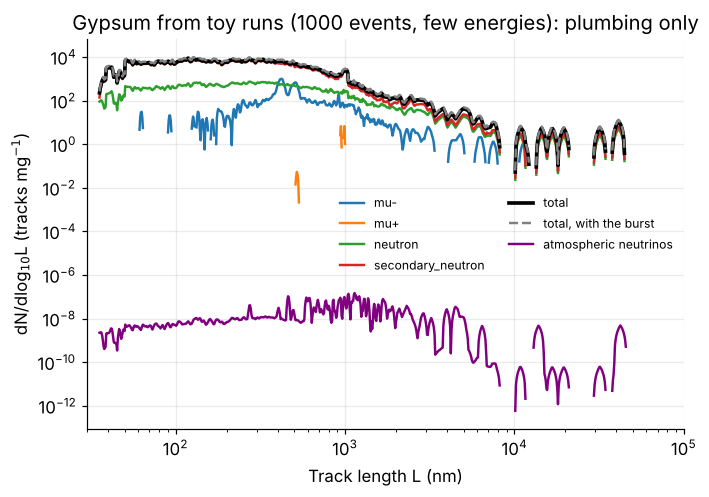

burst / baseline, total tracks: 1.173


In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.6))
for s in gyp.available_species():
    y = cr_base[s] / dlog
    ax.loglog(x_mid, np.where(y > 0, y, np.nan), lw=1.6, label=s)
ax.loglog(x_mid, np.where(cr_base["total"] > 0, cr_base["total"] / dlog, np.nan), color="k", lw=2.4, label="total")
ax.loglog(x_mid, np.where(cr_burst["total"] > 0, cr_burst["total"] / dlog, np.nan), color="0.5", lw=1.6, ls="--",
          label="total, with the burst")
ax.loglog(x_mid, np.where(nu["total"] > 0, nu["total"] / dlog, np.nan), color="purple", lw=1.6,
          label="atmospheric neutrinos")
ax.set(xlabel="Track length L (nm)", ylabel=r"dN/dlog$_{10}$L (tracks mg$^{-1}$)", xlim=(30, 1e5),
       title="Gypsum from toy runs (1000 events, few energies): plumbing only")
ax.legend(fontsize=8, ncol=2)
fig.savefig("figures/17_gypsum_toy_runs.png", dpi=200, bbox_inches="tight")
plt.show()
print(f"burst / baseline, total tracks: {cr_burst['total'].sum() / cr_base['total'].sum():.3f}")